In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import pro_ang1, legendre, chebyt
from sklearn.linear_model import LinearRegression


In [2]:
def Orders(s):
    """Return (i, j) with (i + 1)(j + 1) <= s + 1."""
    return [
        (i, j)
        for i in range(s + 1)
        for j in range((s + 1) // (i + 1))
    ]

In [3]:


# Training sample sizes: 10 logarithmically spaced values
#Nsamples = np.logspace(1, 4, 10).astype(int)
Nsamples = np.linspace(10, 10000, 5).astype(int)

# Slepian bandwidth for the 1D exponential
w = 8

# Fixed test-set size
Ntest = 1000

# Current experiment: five basis functions
Para_slep = [25]

# Use one repetition while debugging; increase for final results
total_runs = 1

In [4]:
# Generate random sample points uniformly on [-1, 1]^2
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    """Generate independent uniform samples on [-1, 1]^2."""
    return rng.uniform(-1, 1, size=(int(n_samples), 2))

In [5]:
# Target function to approximate
def funct(z):
    """
    Evaluate g_3(x, y) = exp(-pi * (x^2 + y^2 + 0.2*x*y)).

    Parameters
    ----------
    z : ndarray, shape (n_samples, 2)
        Sample coordinates (x, y).

    Returns
    -------
    ndarray, shape (n_samples,)
        Target function values.
    """
    x, y = z[:, 0], z[:, 1]
    return np.exp(-np.pi * (x**2 + y**2 + 0.2*x*y))


In [6]:
def Cheby(X, Y, j, k):
    norm_x = np.sqrt(np.pi) if j == 0 else np.sqrt(np.pi / 2)
    norm_y = np.sqrt(np.pi) if k == 0 else np.sqrt(np.pi / 2)

    Tx = chebyt(j)(X) / norm_x
    Ty = chebyt(k)(Y) / norm_y

    return Tx * Ty

In [7]:
def MatrixC(samp, k):
    """Construct the 2D Chebyshev design matrix for hyperbolic-cross order k."""
    Ords = Orders(k)
    A = np.zeros((len(samp), len(Ords)))

    for m, (x, y) in enumerate(samp):
        for i, (j, ell) in enumerate(Ords):
            A[m, i] = Cheby(x, y, j, ell)

    return A

In [8]:
def Legend(X, Y, j, k):
    """Evaluate the normalized 2D tensor-product Legendre basis."""
    norm_x = np.sqrt(2 / (2 * j + 1))
    norm_y = np.sqrt(2 / (2 * k + 1))

    Px = legendre(j)(X) / norm_x
    Py = legendre(k)(Y) / norm_y

    return Px * Py


In [9]:
def MatrixL(samp, k):
    """Construct the 2D Legendre design matrix for hyperbolic-cross order k."""
    Ords = Orders(k)
    A = np.zeros((len(samp), len(Ords)))

    for m, (x, y) in enumerate(samp):
        for i, (j, ell) in enumerate(Ords):
            A[m, i] = Legend(x, y, j, ell)

    return A

In [10]:
def NorSlep(j, c):
    """Approximate the L2([-1, 1]) norm of the angular Slepian function."""
    theta = np.linspace(-1, 1, 1001)
    values = pro_ang1(0, j, c, theta)[0]

    # Exclude endpoints, where pro_ang1 returns NaN
    values = values[1:-1]
    theta = theta[1:-1]

    return np.sqrt(np.trapezoid(np.abs(values)**2, theta))


norms_ = np.array([NorSlep(j, w) for j in range(Para_slep[-1] + 1)])

In [11]:
def PSWF(x, j, c):
    """Evaluate the normalized 1D prolate spheroidal angular function."""
    b = 0
    psaf_values = pro_ang1(b, j, c, x)[0]
    return psaf_values / norms_[j]


In [12]:
def product_of_pswf(x1, x2, i, j, c):
    """Evaluate the 2D tensor-product Slepian basis function."""
    return PSWF(x1, i, c) * PSWF(x2, j, c)

In [13]:
def Matrix(samp, k):
    """Construct the 2D Slepian design matrix for hyperbolic-cross order k."""
    Ords = Orders(k)
    A = np.zeros((len(samp), len(Ords)))

    for m, (x, y) in enumerate(samp):
        for i, (j, ell) in enumerate(Ords):
            A[m, i] = product_of_pswf(x, y, j, ell, w)

    return A

In [14]:
# Allocate error arrays
MSE_cheby = np.zeros((len(Para_slep), len(Nsamples), total_runs))
MSE_leg   = np.zeros_like(MSE_cheby)
MSE_slep  = np.zeros_like(MSE_cheby)

start_time = time.time()
total_iterations = total_runs * len(Para_slep) * len(Nsamples)
counter = 0

for run in range(total_runs):

    # Generate the largest training set once
    SamSet_ = generate_samples(Nsamples[-1])
    y_ = funct(SamSet_)

    # Independent test set of fixed size
    TestSet = generate_samples(Ntest)
    Values_test = funct(TestSet)

    for orde, n in enumerate(Para_slep):

        # n is the manuscript's HC order;
        # Orders(n-1) implements Lambda_HC_{n-1}
        s = n - 1

        # Construct design matrices for this order
        A_c_ = MatrixC(SamSet_, s)
        A_l_ = MatrixL(SamSet_, s)
        A_s_ = Matrix(SamSet_, s)

        test_cheby = MatrixC(TestSet, s)
        test_leg   = MatrixL(TestSet, s)
        test_slep  = Matrix(TestSet, s)

        for k, m in enumerate(Nsamples):

            # Use the first m training samples
            A_c = A_c_[:m, :]
            A_l = A_l_[:m, :]
            A_s = A_s_[:m, :]
            y = y_[:m]

            # Chebyshev least squares
            coef_c = np.linalg.lstsq(A_c, y, rcond=None)[0]
            pred_c = test_cheby @ coef_c
            MSE_cheby[orde, k, run] = (
                np.linalg.norm(pred_c - Values_test) / np.sqrt(Ntest)
            )

            # Legendre least squares
            coef_l = np.linalg.lstsq(A_l, y, rcond=None)[0]
            pred_l = test_leg @ coef_l
            MSE_leg[orde, k, run] = (
                np.linalg.norm(pred_l - Values_test) / np.sqrt(Ntest)
            )

            # Slepian least squares
            coef_s = np.linalg.lstsq(A_s, y, rcond=None)[0]
            pred_s = test_slep @ coef_s
            MSE_slep[orde, k, run] = (
                np.linalg.norm(pred_s - Values_test) / np.sqrt(Ntest)
            )

            counter += 1
            elapsed = time.time() - start_time
            remaining = elapsed * (total_iterations - counter) / counter

            print(
                f"Run {run + 1}/{total_runs}, n={n}, m={m}: "
                f"RMSE (Cheby, Legendre, Slepian) = "
                f"({MSE_cheby[orde,k,run]:.4e}, "
                f"{MSE_leg[orde,k,run]:.4e}, "
                f"{MSE_slep[orde,k,run]:.4e}); "
                f"{100 * counter / total_iterations:.1f}% complete; "
                f"~{remaining:.1f}s remaining"
            )

Run 1/1, n=25, m=10: RMSE (Cheby, Legendre, Slepian) = (3.3553e-01, 3.4407e-01, 3.4810e-01); 20.0% complete; ~1030.9s remaining
Run 1/1, n=25, m=2507: RMSE (Cheby, Legendre, Slepian) = (5.2777e-03, 5.2777e-03, 6.0863e-05); 40.0% complete; ~386.6s remaining
Run 1/1, n=25, m=5005: RMSE (Cheby, Legendre, Slepian) = (5.3882e-03, 5.3882e-03, 6.0636e-05); 60.0% complete; ~171.8s remaining
Run 1/1, n=25, m=7502: RMSE (Cheby, Legendre, Slepian) = (5.3471e-03, 5.3471e-03, 6.0361e-05); 80.0% complete; ~64.4s remaining
Run 1/1, n=25, m=10000: RMSE (Cheby, Legendre, Slepian) = (5.2404e-03, 5.2404e-03, 6.0202e-05); 100.0% complete; ~0.0s remaining


In [15]:
from scipy.linalg import lstsq

m = 100
b = y_[:m]

for name, A, A_test in [
    ("Chebyshev", A_c_[:m, :], test_cheby),
    ("Legendre",  A_l_[:m, :], test_leg),
]:
    # Original NumPy least-squares solver
    coef_np = np.linalg.lstsq(A, b, rcond=None)[0]
    pred_np = A_test @ coef_np
    rmse_np = np.linalg.norm(pred_np - Values_test) / np.sqrt(Ntest)

    # SVD-based least-squares solver
    coef_svd, *_ = lstsq(A, b, lapack_driver="gelsd")
    pred_svd = A_test @ coef_svd
    rmse_svd = np.linalg.norm(pred_svd - Values_test) / np.sqrt(Ntest)

    print(f"\n{name}")
    print(f"Condition number:       {np.linalg.cond(A):.4e}")
    print(f"NumPy coefficient norm: {np.linalg.norm(coef_np):.4e}")
    print(f"SVD coefficient norm:   {np.linalg.norm(coef_svd):.4e}")
    print(f"NumPy test RMSE:        {rmse_np:.6e}")
    print(f"SVD test RMSE:          {rmse_svd:.6e}")


Chebyshev
Condition number:       1.5398e+05
NumPy coefficient norm: 2.2243e+01
SVD coefficient norm:   2.2243e+01
NumPy test RMSE:        2.776721e+00
SVD test RMSE:          2.776721e+00

Legendre
Condition number:       5.4791e+04
NumPy coefficient norm: 4.8094e+00
SVD coefficient norm:   4.8094e+00
NumPy test RMSE:        2.776721e+00
SVD test RMSE:          2.776721e+00


In [16]:
m = 100
b = y_[:m]

for name, A, A_test in [
    ("Chebyshev", A_c_[:m, :], test_cheby),
    ("Legendre", A_l_[:m, :], test_leg),
]:
    coef = np.linalg.lstsq(A, b, rcond=None)[0]

    train_pred = A @ coef
    test_pred = A_test @ coef

    print(f"\n{name}")
    print("Training RMSE:",
          np.linalg.norm(train_pred - b) / np.sqrt(m))
    print("Test RMSE:",
          np.linalg.norm(test_pred - Values_test) / np.sqrt(Ntest))
    print("Max absolute test prediction:", np.max(np.abs(test_pred)))
    print("Max absolute true test value:", np.max(np.abs(Values_test)))


Chebyshev
Training RMSE: 0.0005907544493581077
Test RMSE: 2.776720560210988
Max absolute test prediction: 39.106296321097346
Max absolute true test value: 0.9984691389585787

Legendre
Training RMSE: 0.0005907544493581386
Test RMSE: 2.7767205602676066
Max absolute test prediction: 39.10629632187356
Max absolute true test value: 0.9984691389585787


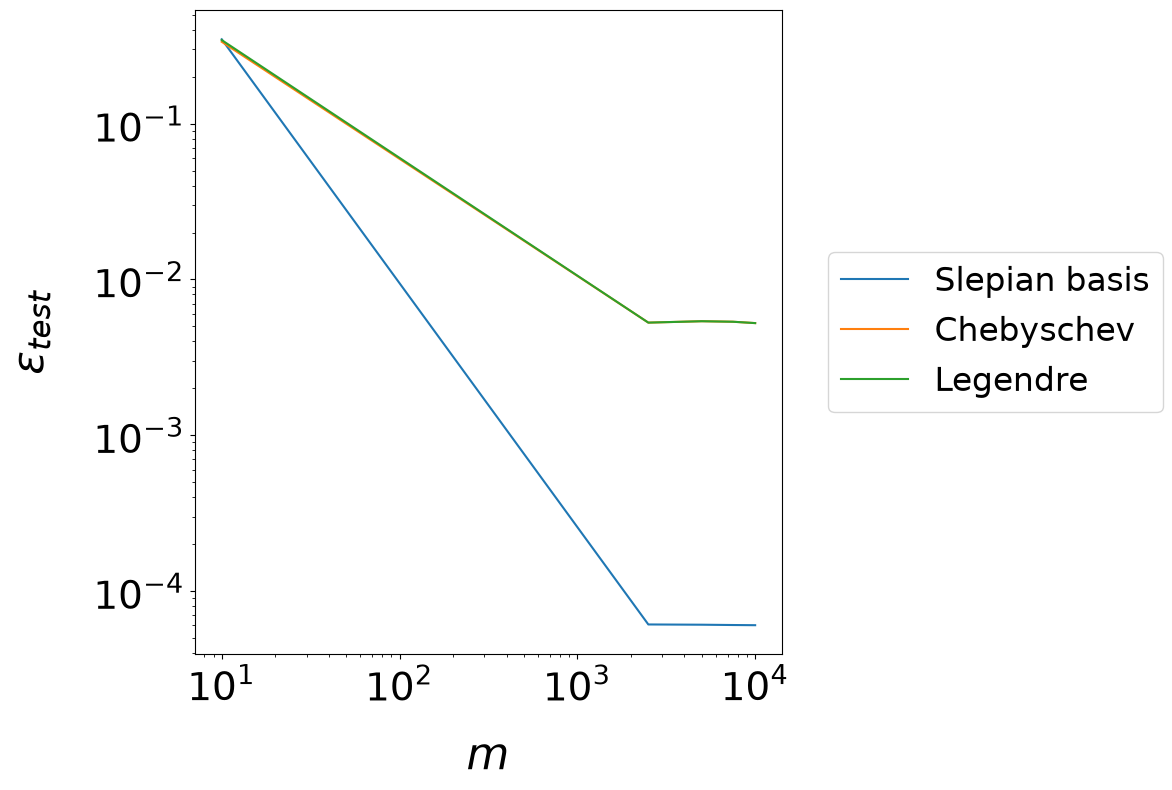

In [17]:
#Plot Error over training set sizes
plt.figure(figsize=(12, 8))  #Size
results_mean_cheby = np.mean(MSE_cheby, axis = 2)
results_lower_cheby = np.std(MSE_cheby, axis = 2)/results_mean_cheby # 90% confidence intervals

results_mean_leg = np.mean(MSE_leg, axis = 2)
results_lower_leg = np.std(MSE_leg, axis = 2)/results_mean_leg # 90% confidence intervals

results_mean = np.mean(MSE_slep, axis = 2)
results_lower= np.std(MSE_slep, axis = 2)/results_mean # 90% confidence intervals


for i in range(len(Para_slep)):
    plt.loglog(Nsamples, results_mean[i,:], label="Slepian basis")
    plt.fill_between(Nsamples, results_mean[i,:]/(1+results_lower[i,:]), results_mean[i,:]*(1+results_lower[i,:]),  alpha=0.2)

    plt.loglog(Nsamples, results_mean_cheby[i,:], label="Chebyschev")
    plt.fill_between(Nsamples, results_mean_cheby[i,:]/(1+results_lower_cheby[i,:]), results_mean_cheby[i,:]*(1+results_lower_cheby[i,:]),  alpha=0.2)

    plt.loglog(Nsamples, results_mean_leg[i,:], label="Legendre")
    plt.fill_between(Nsamples, results_mean_leg[i,:]/(1+results_lower_leg[i,:]), results_mean_leg[i,:]*(1+results_lower_leg[i,:]),  alpha=0.2)



plt.xlabel(r'$m$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{test}$', fontsize=32, labelpad=28)


# Increase font size of axis tick labels
plt.tick_params(axis='both', which='major', labelsize=28)  # Major ticks
plt.tick_params(axis='both', which='minor', labelsize=28)  # Minor ticks

plt.legend(fontsize=28, loc='lower left')

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),  # Place the legend to the right of the plot
    ncol=1  # Single column for legend entries
)

plt.tight_layout()  

plt.savefig("errorvsparams2D_withNoy.pdf")


plt.show()

In [147]:
import os

# Número total de núcleos disponibles para Python
total_cores = os.cpu_count()
print("Núcleos totales:", total_cores)

Núcleos totales: 32
